## Treemaps

In [1]:
import pandas
import plotly.express as px

In [2]:
# Sales Data Example

data = {
    "Category": [
        "Electronics",
        "Electronics",
        "Electronics",
        "Furniture",
        "Furniture",
        "Furniture",
        "Clothing",
        "Clothing",
        "Clothing",
    ],
    "Subcategory": [
        "Laptops",
        "Smartphones",
        "Tablets",
        "Chairs",
        "Tables",
        "Sofas",
        "Men",
        "Women",
        "Kids",
    ],
    "Sales": [120000, 80000, 30000, 50000, 40000, 20000, 70000, 90000, 40000],
}

df = pandas.DataFrame(data)

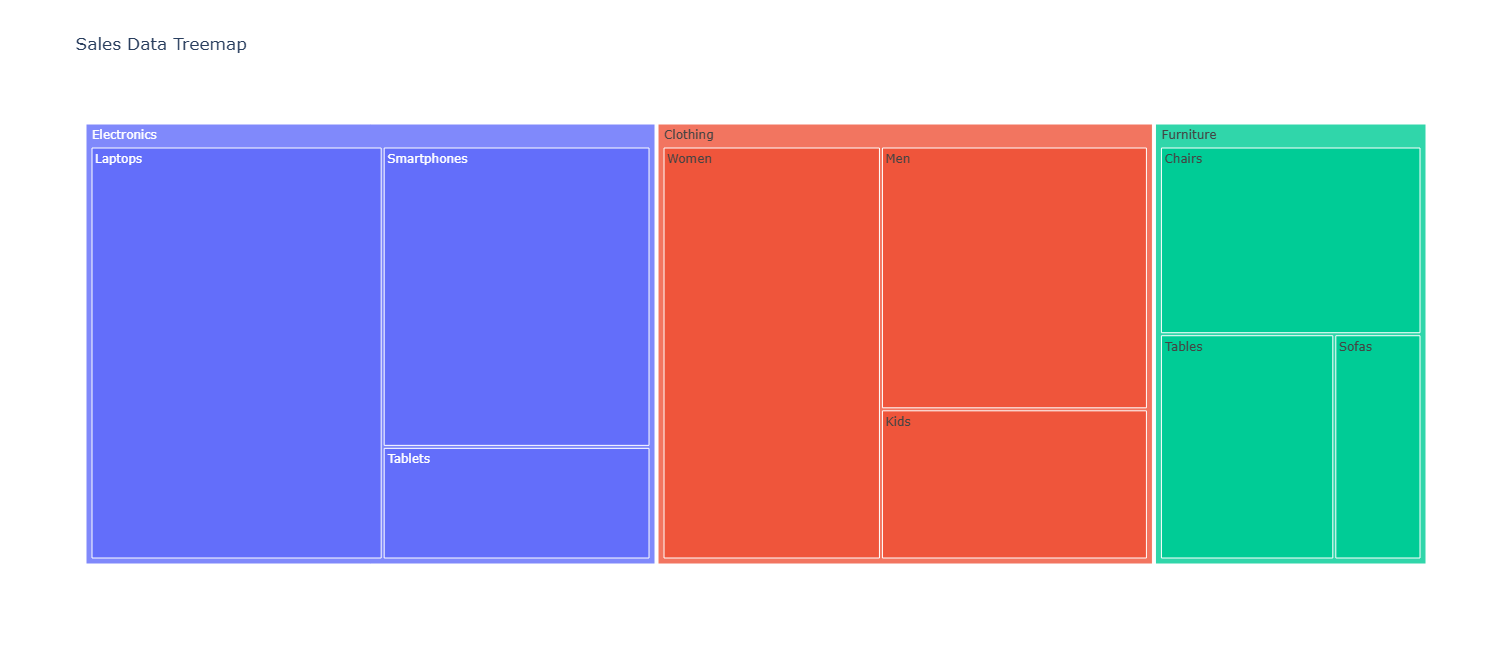

In [3]:
fig = px.treemap(
    df,
    path=["Category", "Subcategory"],  # Definisikan struktur hierarkis
    values="Sales",  # Ukuran setiap persegi panjang
    title="Sales Data Treemap",  # Judul treemap
    height=650,
)

fig.write_image("../outputs/treemaps_example.png", scale=2)
fig.show()

## Pivot Charts

In [4]:
import matplotlib.pyplot as plt
import numpy as np

In [5]:
# Buat parameter untuk data dummy
num_quarters = 4
num_categories = 4
num_subcategories = 3
num_samples = num_quarters * num_categories * num_subcategories * 50

# Buat sample data penjualan
np.random.seed(42)

In [6]:
# Buat sample data
dates = np.repeat(["Q1", "Q2", "Q3", "Q4"], 50 * num_categories * num_subcategories)

In [7]:
categories = np.tile(
    np.random.choice(
        ["Laptops", "Desktops", "Peripherals", "Software"], size=num_quarters * 50
    ),
    num_categories * num_subcategories,
)

In [8]:
subcategories = np.tile(
    np.random.choice(
        ["Accessories", "Components", "Software Suites"], size=num_quarters * 50
    ),
    num_categories * num_subcategories,
)

In [9]:
sales_values = np.random.randint(1000, 5000, size=num_samples)

In [10]:
# Buat dataframe
df_sales = pandas.DataFrame(
    {
        "Date": dates,
        "Category": categories,
        "Subcategory": subcategories,
        "Sales": sales_values,
    }
)

In [11]:
# Buat tabel pivot
pivot_table = df_sales.pivot_table(
    index="Date", columns=["Category", "Subcategory"], values="Sales", aggfunc=np.sum
)

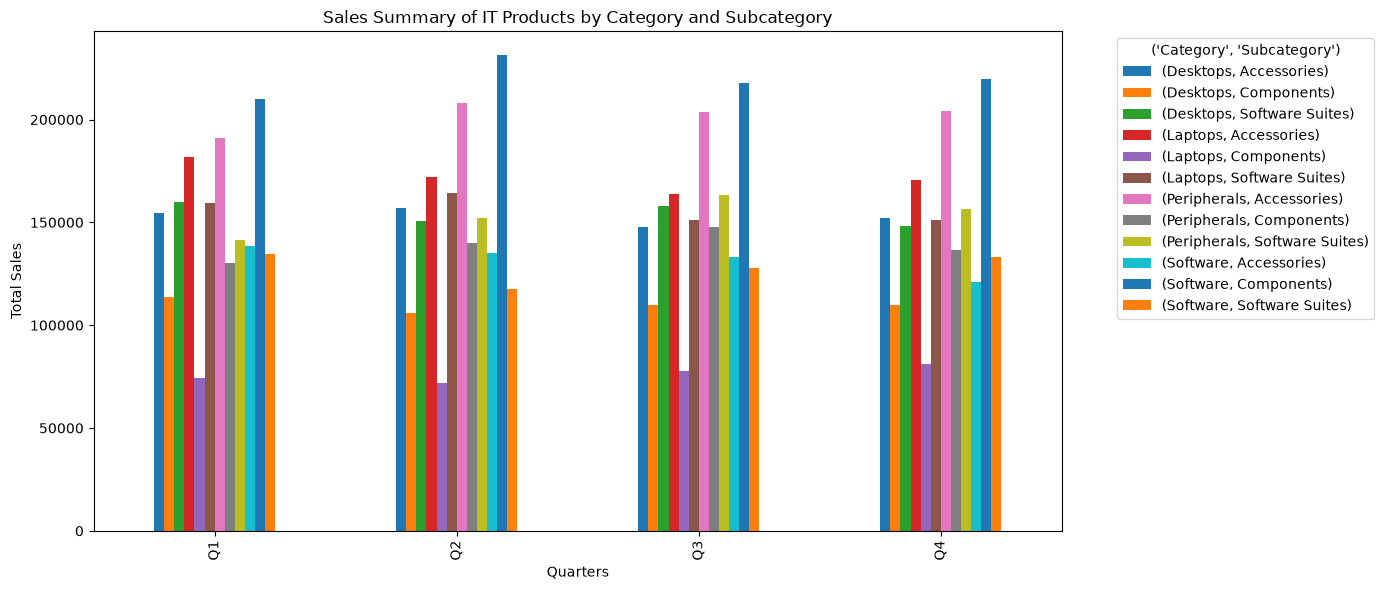

In [12]:
# Buat grafik pivot
pivot_table.plot(kind="bar", figsize=(14, 6))

plt.title("Sales Summary of IT Products by Category and Subcategory")
plt.xlabel("Quarters")
plt.ylabel("Total Sales")
plt.grid(False)
plt.legend(
    title=("Category", "Subcategory"), bbox_to_anchor=(1.05, 1), loc="upper left"
)
plt.tight_layout()

plt.savefig("../outputs/pivot_charts_example.png", dpi=200, bbox_inches="tight")
plt.show()